In [1]:
from momentum import momentum_strategy
from backtester import run_backtest
import metrics
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
prices = pd.read_csv("data/prices.csv", index_col=0, parse_dates=True)
returns = prices.pct_change()

In [11]:
lookbacks = [3,6,9,12]
top_ns = [2,3,5]
results = {}
starts = []

for lookback in lookbacks:
    for top_n in top_ns:
        weights = momentum_strategy(prices, lookback=lookback, top_n=top_n)
        results[(lookback, top_n)] = run_backtest(weights, returns, cost=0.001)
        starts.append((weights.shift(1).sum(axis=1) > 0).idxmax())

common_start = max(starts)

sharpe_ratios = pd.DataFrame(index=lookbacks, columns=top_ns, dtype=float)
for (lookback, top_n), strat_returns in results.items():
    sharpe_ratios.loc[lookback, top_n] = metrics.sharpe_ratio(strat_returns.loc[common_start:])

spy_sharpe = metrics.sharpe_ratio(returns["SPY"].loc[common_start:])
print(common_start, spy_sharpe)
sharpe_ratios

2011-02-01 00:00:00 0.8642731683163246


,2,3,5
3,0.654436,0.661027,0.842990
6,0.486739,0.679643,0.788160
9,0.398178,0.629173,0.872396
12,0.601190,0.733577,0.760301


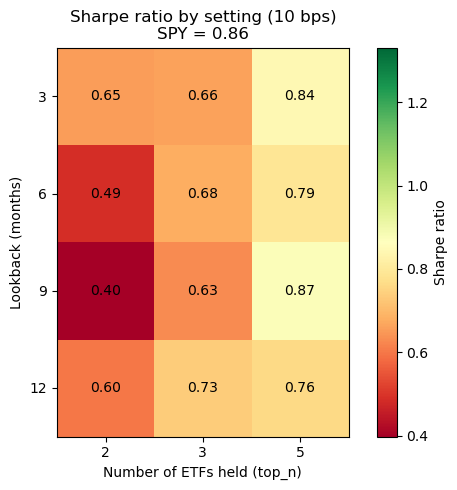

In [13]:
from matplotlib.colors import TwoSlopeNorm

fig, ax = plt.subplots(figsize=(6, 5))

d = (sharpe_ratios - spy_sharpe).abs().max().max()
norm = TwoSlopeNorm(vcenter=spy_sharpe, vmin=spy_sharpe - d, vmax=spy_sharpe + d)
im = ax.imshow(sharpe_ratios.values, cmap="RdYlGn", norm=norm)

ax.set_xticks(range(len(top_ns)))
ax.set_xticklabels(top_ns)
ax.set_yticks(range(len(lookbacks)))
ax.set_yticklabels(lookbacks)
ax.set_xlabel("Number of ETFs held (top_n)")
ax.set_ylabel("Lookback (months)")
ax.set_title(f"Sharpe ratio by setting (10 bps)\nSPY = {spy_sharpe:.2f}")

for i in range(len(lookbacks)):
    for j in range(len(top_ns)):
        ax.text(j, i, f"{sharpe_ratios.iloc[i, j]:.2f}", ha="center", va="center")

fig.colorbar(im, ax=ax, label="Sharpe ratio")
fig.tight_layout()
fig.savefig("figures/sharpe_sweep_heatmap.png")
plt.show()

Sharpe ratios range from 0.40 to 0.87 across the 12 settings (a spread of 0.47),
so results are sensitive to the choice of lookback and number of holdings. The
original 12 month, top3 choice (0.73) is typical, sitting near the middle of
the range (median being 0.67). Only one version beats SPY (0.86): 9 months, top 5, at 0.87, and only
by a very small margin. Reporting that best version alone would be misleading,
because picking the best of 12 attempts after seeing the results biases its
performance upwards: some of its advantage is likely luck rather than a real edge.


In every row, the Sharpe ratio increases as top_n rises from 2 to 5, making the number
of holdings a more consistent driver of performance than the lookback length. Holding
more ETFs diversifies the portfolio: it reduces the impact of any single bad pick and
makes the strategy behave more like the overall ETF universe, which is itself closely
tied to the US market.

In [22]:
sharpe_ratios_insample = pd.DataFrame(index=lookbacks, columns=top_ns, dtype=float)
sharpe_ratios_outsample = pd.DataFrame(index=lookbacks, columns=top_ns, dtype=float)
spy_sharpe_insample = metrics.sharpe_ratio(returns["SPY"].loc[common_start:"2018"])
spy_sharpe_outsample = metrics.sharpe_ratio(returns["SPY"].loc["2019":])

for (lookback, top_n), strat_returns in results.items():
    sharpe_ratios_insample.loc[lookback, top_n] = metrics.sharpe_ratio(strat_returns.loc[common_start:"2018"])
    sharpe_ratios_outsample.loc[lookback, top_n] = metrics.sharpe_ratio(strat_returns.loc["2019":])



In [18]:
sharpe_ratios_insample

,2,3,5
3,0.543653,0.604993,0.810165
6,0.442834,0.630907,0.680411
9,0.291734,0.511666,0.668963
12,0.423539,0.326444,0.472899


In [16]:
sharpe_ratios_outsample

,2,3,5
3,0.750848,0.715197,0.882132
6,0.528411,0.727332,0.885535
9,0.485531,0.733227,1.055324
12,0.752614,1.092776,1.022979


In [23]:
spy_sharpe_outsample
spy_sharpe_insample

np.float64(0.7911473085413303)

In [24]:
sharpe_ratios_insample.stack().corr(sharpe_ratios_outsample.stack(), method="spearman")

np.float64(0.2377622377622378)

The best in-sample setting (3 months, top 5, Sharpe 0.81) did not stay the best: out of
sample it scored 0.88, ranking 5th of 12 and below SPY's 0.94. All 12 settings had higher
Sharpe ratios after 2019, but SPY did too (in-sample 0.79, out-of-sample 0.94), so much of
this reflects a stronger market period rather than the strategy improving. Rankings were
unstable: the original 12/3 was the second worst in-sample (0.33) but the best out of
sample (1.09), and the rank correlation between in-sample and out-of-sample Sharpe ratios
was 0.24. Choosing settings based on past backtest performance would not have reliably
picked a good setting here, which suggests most of the differences between settings are
noise rather than genuine differences in quality.

The top_n pattern largely holds in both halves. Top 5 beats top 2 for every lookback in
both periods, and averaged across lookbacks the Sharpe ratio rises with top_n in each
half. The increase is
not perfectly smooth, but
unlike the best individual setting, the benefit of holding more ETFs is consistent across
periods, making it the most robust finding of the sweep.